# 00 · Preparación: las herramientas para leer y ejecutar el libro

Este cuaderno es el punto de entrada al grupo de lectura de *Reinforcement Learning: An Overview*. Es material preparatorio propio de la guía: no corresponde a un capítulo 0 del libro.

**Objetivo:** practicar las operaciones que aparecerán una y otra vez: trabajar con arrays, calcular esperanzas, actualizar creencias, multiplicar matrices, seguir un gradiente y comparar resultados.

No necesitas conocer RL. Basta con reconocer una variable, una función y un bucle de Python. Si acabas de empezar, lee el código en voz alta y cambia un número cada vez. Una primera sesión de 60–90 minutos puede bastar para recorrer los ejemplos; reserva otra si quieres resolver la autoevaluación con calma. Son tiempos orientativos.

**Cómo trabajar:** ejecuta las celdas en orden, predice el resultado antes de mirarlo y después cambia una entrada. Al final hay doce preguntas, un corrector y soluciones desplegables. Las respuestas empiezan vacías: ejecutar todo el notebook no contesta por ti.

## 1. Preparar Python y leer una operación

Solo usamos NumPy para los cálculos y Matplotlib para las figuras. No se necesitan descargas de datos, servicios externos ni otros archivos del repositorio.

Una lista representa una secuencia. Un array añade operaciones numéricas sobre todos sus elementos. La forma, o **shape**, indica cuántos elementos hay en cada eje: no es un detalle de presentación, sino parte del significado de los datos.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 2026
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "grid.alpha": 0.25})

lista = [1, 2, 3]
vector = np.array(lista, dtype=float)
print("Repetir una lista:", lista * 2)
print("Multiplicar cada elemento del array:", vector * 2)
print("Forma del vector:", vector.shape)


Repetir una lista: [1, 2, 3, 1, 2, 3]
Multiplicar cada elemento del array: [2. 4. 6.]
Forma del vector: (3,)


La lista repetida tiene seis elementos. El array conserva tres y duplica sus valores. Esta diferencia explica errores frecuentes al traducir una fórmula a Python.

## 2. NumPy: decidir qué significa cada eje

Imagina tres ejecuciones de un algoritmo y cuatro momentos de evaluación. Cada fila es una ejecución; cada columna, un instante.

La media sobre **axis=0** elimina el eje de las filas y produce una curva media de cuatro puntos. La media sobre **axis=1** resume los cuatro instantes de cada ejecución. Son preguntas distintas. Para comparar rendimiento final, usamos la última columna, no la media de toda la historia.


In [2]:
resultados = np.array([[1, 2, 3, 4],
                       [2, 3, 4, 5],
                       [0, 2, 4, 6]], dtype=float)
print("Forma: réplicas × instantes =", resultados.shape)
print("Media en cada instante:", resultados.mean(axis=0))
print("Media temporal de cada réplica:", resultados.mean(axis=1))
print("Último resultado de cada réplica:", resultados[:, -1])
assert resultados.mean(axis=0).shape == (4,)
assert resultados.mean(axis=1).shape == (3,)


Forma: réplicas × instantes = (3, 4)
Media en cada instante: [1.     2.3333 3.6667 5.    ]
Media temporal de cada réplica: [2.5 3.5 3. ]
Último resultado de cada réplica: [4. 5. 6.]


El broadcasting permite combinar dimensiones compatibles. Para centrar cada fila necesitamos conservar una columna por fila: **keepdims=True** devuelve forma (3, 1), que puede restarse de (3, 4). Quitarla puede producir un error o, en tablas cuadradas, una operación válida con significado equivocado.


In [3]:
media_por_fila = resultados.mean(axis=1, keepdims=True)
centrados = resultados - media_por_fila
print("Forma de las medias:", media_por_fila.shape)
print("Datos centrados por fila:\n", centrados)
np.testing.assert_allclose(centrados.mean(axis=1), 0, atol=1e-12)

# Las vistas pueden compartir memoria; una copia sirve para una variante independiente.
variante = resultados[:, -1].copy()
variante[0] = -100
assert resultados[0, -1] == 4


Forma de las medias: (3, 1)
Datos centrados por fila:
 [[-1.5 -0.5  0.5  1.5]
 [-1.5 -0.5  0.5  1.5]
 [-3.  -1.   1.   3. ]]


**Práctica breve:** cambia el número de filas y vuelve a predecir las formas. Después explica qué selecciona resultados[1, :2] sin ejecutar la expresión.

## 3. Producto escalar: traducir una suma ponderada

El producto $w^\top x$ multiplica componentes correspondientes y suma. En NumPy usamos **@**. El operador **\*** multiplica elemento a elemento y todavía no suma.

Una función de valor lineal puede escribirse como $V_w(s)=w^\top\phi(s)$: las características del estado forman el vector $\phi(s)$ y los pesos indican cómo combinarlas. La misma operación sirve para promediar recompensas con probabilidades.


In [4]:
w = np.array([2.0, -1.0])
caracteristicas = np.array([3.0, 4.0])
print("Productos individuales:", w * caracteristicas)
print("Producto escalar:", w @ caracteristicas)

X = np.array([[3.0, 4.0], [1.0, 0.0], [0.0, 2.0]])
predicciones = X @ w
print("Una predicción por fila:", predicciones)
np.testing.assert_allclose(predicciones, [2, 2, -2])


Productos individuales: [ 6. -4.]
Producto escalar: 2.0
Una predicción por fila: [ 2.  2. -2.]


Antes de multiplicar matrices, escribe sus formas. Una matriz (3, 2) por un vector (2,) produce un vector (3,). Las dimensiones interiores deben coincidir.

## 4. Probabilidad: promedio no significa resultado observado

Una recompensa entrega 10 con probabilidad 0.2 y cero el resto de veces. Su esperanza es

$$\mathbb E[R]=\sum_i p_i r_i=2.$$

Ninguna ejecución recibe 2. La esperanza es una media ponderada sobre resultados posibles. La varianza resume dispersión alrededor de esa media:

$$\operatorname{Var}(R)=\sum_i p_i(r_i-\mathbb E[R])^2.$$

Aquí su valor es 16, y la desviación estándar es 4. No confundas varianza de las recompensas con incertidumbre de la media estimada.


In [5]:
premios = np.array([0.0, 10.0])
probabilidades = np.array([0.8, 0.2])
assert np.all(probabilidades >= 0) and np.isclose(probabilidades.sum(), 1)

esperanza = probabilidades @ premios
varianza = probabilidades @ (premios-esperanza)**2
print("Esperanza:", esperanza, "Varianza:", varianza, "Desviación:", np.sqrt(varianza))
assert np.isclose(esperanza, 2)
assert np.isclose(varianza, 16)


Esperanza: 2.0 Varianza: 16.0 Desviación: 4.0


Si la política elige entre dos acciones, podemos promediar sus recompensas esperadas mediante sus probabilidades. Esta es una aplicación de la esperanza total: primero condicionamos a la acción y luego promediamos acciones.


In [6]:
politica = np.array([0.75, 0.25])
premios_medios_por_accion = np.array([2.0, 6.0])
print("Recompensa esperada de la política:", politica @ premios_medios_por_accion)


Recompensa esperada de la política: 3.0


Una política aleatoria sigue siendo una regla bien definida. Lo aleatorio es qué acción produce en una ejecución concreta.

## 5. Monte Carlo: aproximar una esperanza con muestras

Cuando no podemos sumar todos los resultados posibles, los muestreamos. La media de muestras independientes aproxima la esperanza. Con varianza finita, su error estándar es $\sigma/\sqrt n$.

La curva de una sola ejecución puede alejarse temporalmente del valor verdadero. Más datos mejoran la precisión típica; no obligan al error observado a disminuir en cada paso. Las transiciones consecutivas de un agente suelen estar correlacionadas, por lo que no siempre podemos aplicar sin ajustes la fórmula de muestras independientes.


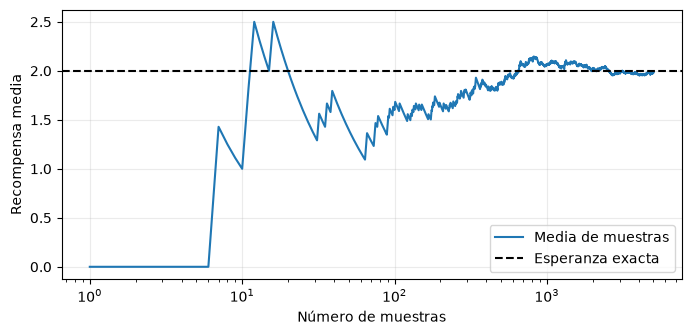

Estimación con 5000 muestras: 1.982


In [7]:
rng = np.random.default_rng(SEMILLA)
muestras = rng.choice(premios, size=5000, p=probabilidades)
media_acumulada = muestras.cumsum() / np.arange(1, len(muestras)+1)
plt.plot(np.arange(1, len(muestras)+1), media_acumulada, label="Media de muestras")
plt.axhline(esperanza, color="black", linestyle="--", label="Esperanza exacta")
plt.xscale("log")
plt.xlabel("Número de muestras")
plt.ylabel("Recompensa media")
plt.legend()
plt.show()
print("Estimación con 5000 muestras:", media_acumulada[-1])


Ahora repetimos el experimento muchas veces para medir la dispersión de las medias, no la de los premios individuales. Multiplicar n por cuatro debería reducir aproximadamente a la mitad esa dispersión.


In [8]:
rng = np.random.default_rng(SEMILLA+1)
for n in [25, 100, 400]:
    medias = rng.choice(premios, size=(1000, n), p=probabilidades).mean(axis=1)
    print(f"n={n:3d}: desviación entre medias={medias.std(ddof=1):.3f}, "
          f"predicción={np.sqrt(varianza/n):.3f}")


n= 25: desviación entre medias=0.796, predicción=0.800
n=100: desviación entre medias=0.388, predicción=0.400


n=400: desviación entre medias=0.202, predicción=0.200


**Práctica breve:** sustituye el premio 10 por 20. Predice antes cómo cambian la esperanza, la varianza y la desviación de las medias. Recalcula todas las cantidades que dependen de ese premio.

## 6. Bayes: actualizar una creencia cuando llega información

Supón que un sensor observa un bit oculto. El bit vale uno con probabilidad previa 0.5 y el sensor acierta un 80% de las veces, tanto para ceros como para unos.

Después de observar un uno:

$$P(s=1\mid o=1)=
\frac{P(o=1\mid s=1)P(s=1)}
{P(o=1\mid s=1)P(s=1)+P(o=1\mid s=0)P(s=0)}.$$

El numerador expresa una posibilidad conjunta; el denominador suma todas las formas de producir esa observación. No intercambies $P(o\mid s)$ con $P(s\mid o)$: son preguntas diferentes.


In [9]:
def posterior_uno(prior, acierto=0.8):
    numerador = acierto * prior
    evidencia = acierto*prior + (1-acierto)*(1-prior)
    return numerador / evidencia

for prior in [0.1, 0.5, 0.9]:
    print(f"Prior={prior}: posterior tras observar 1={posterior_uno(prior):.4f}")
assert np.isclose(posterior_uno(0.5), 0.8)


Prior=0.1: posterior tras observar 1=0.3077
Prior=0.5: posterior tras observar 1=0.8000
Prior=0.9: posterior tras observar 1=0.9730


Con un prior pequeño, una señal positiva no garantiza una creencia posterior alta. Hay que combinar evidencia y frecuencia previa.

## 7. Aprender una probabilidad y seguir viendo azar

Ahora desconocemos la probabilidad de éxito de un brazo de bandit. Un prior Beta(1,1) representa una distribución uniforme sobre probabilidades entre cero y uno. Tras observar éxitos y fracasos:

$$\alpha'=1+\text{éxitos},\qquad
\beta'=1+\text{fracasos},\qquad
\mathbb E[p\mid D]=\frac{\alpha'}{\alpha'+\beta'}.$$

La distribución Beta es sobre una **probabilidad desconocida**, no sobre el siguiente resultado binario. Su dispersión representa incertidumbre epistémica. Aunque aprendamos exactamente que p=0.7, el siguiente ensayo sigue siendo aleatorio.


Beta(4,2): media posterior=0.667


Beta(31,11): media posterior=0.738


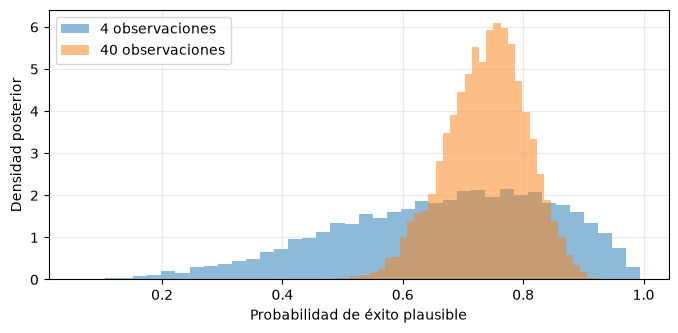

In [10]:
rng = np.random.default_rng(SEMILLA+2)
for exitos, fracasos in [(3, 1), (30, 10)]:
    alpha, beta = 1+exitos, 1+fracasos
    posibles_probabilidades = rng.beta(alpha, beta, size=10000)
    print(f"Beta({alpha},{beta}): media posterior={alpha/(alpha+beta):.3f}")
    plt.hist(posibles_probabilidades, bins=40, density=True, alpha=0.5,
             label=f"{exitos+fracasos} observaciones")
plt.xlabel("Probabilidad de éxito plausible")
plt.ylabel("Densidad posterior")
plt.legend()
plt.show()


Las dos proporciones observadas son iguales, pero el prior pesa menos con más datos y la distribución se concentra más. No esperes medias posteriores exactamente iguales con un prior fijo y distinto tamaño muestral.

## 8. Álgebra de un proceso de Markov

Una matriz de transición P contiene probabilidades de pasar de un estado a otro. Adoptamos la convención de filas: P[i,j] es la probabilidad del siguiente estado j al partir de i. Cada fila suma uno.

Si d es una distribución fila del estado actual, **d @ P** da la distribución del siguiente estado. En cambio, **P @ V** calcula, para cada estado inicial, el valor esperado de una cantidad V en el siguiente estado.


In [11]:
P = np.array([[0.8, 0.2], [0.1, 0.9]])
d = np.array([1.0, 0.0])
valores_futuros = np.array([2.0, 5.0])
np.testing.assert_allclose(P.sum(axis=1), 1)
print("Distribución siguiente:", d @ P)
print("Valor futuro esperado desde cada estado:", P @ valores_futuros)
np.testing.assert_allclose(P @ valores_futuros, [2.6, 4.7])


Distribución siguiente: [0.8 0.2]
Valor futuro esperado desde cada estado: [2.6 4.7]


En RL la transición puede depender también de la acción. Si ya fijamos la política, podemos promediar esa acción y volver a una matriz de transición entre estados.

### Un sistema lineal que anticipa Bellman

Recibimos recompensa por estado r y descontamos el futuro con gamma. El valor total satisface

$$V=r+\gamma PV,\qquad (I-\gamma P)V=r.$$

Usamos un solucionador lineal, sin calcular explícitamente una inversa. Con un número finito de estados y $0\leq\gamma<1$, el sistema de este proceso está bien definido. Después comprobamos el residuo de la ecuación.


In [12]:
r = np.array([1.0, 0.0])
gamma = 0.9
V = np.linalg.solve(np.eye(len(P))-gamma*P, r)
residuo = V-(r+gamma*P@V)
print("Valores:", V)
print("Residuo de Bellman:", residuo)
np.testing.assert_allclose(residuo, 0, atol=1e-12)

# Un estado que da 2 y vuelve a sí mismo: V=2+0.9V.
valor_un_estado = np.linalg.solve(np.array([[1-0.9]]), np.array([2.0]))[0]
assert np.isclose(valor_un_estado, 20)


Valores: [5.1351 2.4324]
Residuo de Bellman: [0. 0.]


## 9. Retorno: dar peso a cada instante

El retorno de una trayectoria es una suma descontada de recompensas:

$$G_0=r_0+\gamma r_1+\gamma^2r_2+\cdots.$$

El primer premio lleva exponente cero. Usaremos r_t para la recompensa producida al actuar en t; otros textos la llaman r_{t+1}. Cambia el nombre del índice, no el cálculo.

El retorno observado G no es lo mismo que el valor V: V es una esperanza sobre trayectorias posibles bajo una política.


In [13]:
def retorno(recompensas, gamma):
    r = np.asarray(recompensas, dtype=float)
    return float((gamma**np.arange(len(r))) @ r)

print("Retorno de [0, 0, 1] con gamma=0.9:", retorno([0, 0, 1], 0.9))
assert np.isclose(retorno([0, 0, 1], 0.9), 0.81)
assert retorno([4, 2, 7], 0) == 4
assert retorno([4, 2, 7], 1) == 13


Retorno de [0, 0, 1] con gamma=0.9: 0.81


Un gamma igual a uno es válido en estos episodios finitos. En un horizonte infinito necesitamos otras condiciones para que la suma converja.

## 10. Cálculo: comprobar una derivada y seguir su dirección

Considera la pérdida $L(\theta)=(\theta-3)^2$. Su derivada es $2(\theta-3)$. Para minimizarla usamos descenso:

$$\theta_{\rm nuevo}=\theta-\eta L'(\theta).$$

Para maximizar una recompensa usaríamos el signo positivo. Una derivada indica una dirección local; no garantiza que un paso arbitrariamente grande mejore el objetivo.

Las diferencias finitas aproximan la derivada mediante pequeñas perturbaciones. Son una buena comprobación en ejemplos pequeños, aunque en modelos grandes entrenamos con derivadas calculadas de otra forma.


In [14]:
def perdida(theta):
    return (theta-3)**2

theta, h = 1.0, 1e-5
analitica = 2*(theta-3)
numerica = (perdida(theta+h)-perdida(theta-h))/(2*h)
print("Derivada analítica:", analitica, "Diferencia finita:", numerica)
np.testing.assert_allclose(analitica, numerica, atol=1e-9)
eta = 0.25
theta_nuevo = theta-eta*analitica
print("Parámetro antes y después:", theta, theta_nuevo)
assert perdida(theta_nuevo) < perdida(theta)


Derivada analítica: -4.0 Diferencia finita: -4.000000000026205
Parámetro antes y después: 1.0 2.0


En esta cuadrática, el error respecto a 3 se multiplica por $1-2\eta$ en cada paso. Si su valor absoluto supera uno, las oscilaciones crecen. Vamos a verlo; esta fórmula concreta no es una garantía para cualquier pérdida.


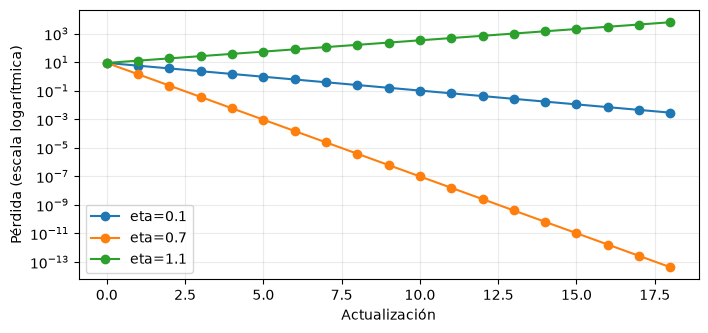

In [15]:
for eta in [0.1, 0.7, 1.1]:
    theta = 0.0
    historia = [perdida(theta)]
    for _ in range(18):
        theta -= eta*2*(theta-3)
        historia.append(perdida(theta))
    plt.plot(historia, "o-", label=f"eta={eta}")
plt.yscale("log")
plt.xlabel("Actualización")
plt.ylabel("Pérdida (escala logarítmica)")
plt.legend()
plt.show()


## 11. Convertir puntuaciones en probabilidades: softmax

Una política categórica suele producir logits, puntuaciones reales sin normalizar, y transformarlos en probabilidades:

$$p_i=\frac{e^{\theta_i}}{\sum_j e^{\theta_j}}.$$

Restar el máximo antes de exponenciar evita desbordamientos sin cambiar el resultado. Sumar la misma constante a todos los logits no cambia sus probabilidades. Un logit no es ya una probabilidad.


Probabilidades: [0.09   0.2447 0.6652] Suma: 0.9999999999999999


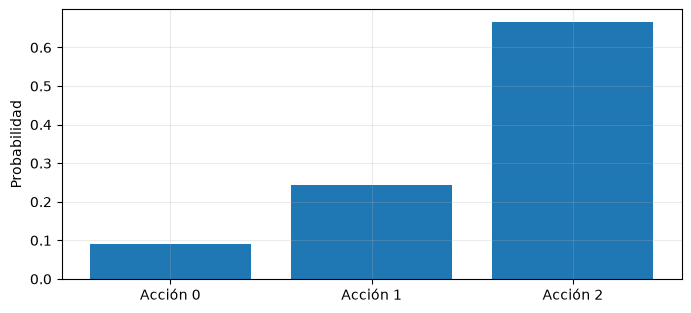

In [16]:
def softmax(theta):
    theta = np.asarray(theta, dtype=float)
    e = np.exp(theta-np.max(theta))
    return e/e.sum()

logits = np.array([1000.0, 1001.0, 1002.0])
p = softmax(logits)
print("Probabilidades:", p, "Suma:", p.sum())
np.testing.assert_allclose(p, softmax(logits-1000))
assert np.isfinite(p).all()
plt.bar(["Acción 0", "Acción 1", "Acción 2"], p)
plt.ylabel("Probabilidad")
plt.show()


Para el gradiente de política necesitaremos $\nabla_\theta\log p(a)=e_a-p$. El vector e_a tiene un uno en la acción elegida y ceros en las demás. Su suma es cero: subir una probabilidad requiere compensar las otras.


In [17]:
accion = 1
score = np.eye(len(p))[accion]-p
h = 1e-5
numerico = np.array([
    (np.log(softmax(logits+h*np.eye(len(p))[j])[accion])
     - np.log(softmax(logits-h*np.eye(len(p))[j])[accion]))/(2*h)
    for j in range(len(p))
])
print("Gradiente de log-probabilidad:", score)
np.testing.assert_allclose(score, numerico, atol=1e-8)
assert np.isclose(score.sum(), 0)


Gradiente de log-probabilidad: [-0.09    0.7553 -0.6652]


No necesitas memorizar toda la derivación antes del capítulo 1. Sí conviene poder explicar qué representan el vector de probabilidades y la acción muestreada.

## 12. Entropía y KL: diversidad y cambio de distribución

La entropía $H(p)=-\sum_i p_i\log p_i$ mide dispersión. Usamos logaritmos naturales, por lo que la unidad son nats. Una distribución determinista tiene entropía cero; la uniforme sobre K categorías tiene entropía $\log K$.

La divergencia $\mathrm{KL}(p\|q)=\sum_i p_i\log(p_i/q_i)$ compara distribuciones. No es simétrica. Si q pone cero donde p tiene masa positiva, la KL es infinita. Para p_i=0 usamos la convención de contribución cero.


In [18]:
def entropia(p):
    p = np.asarray(p, dtype=float)
    positivos = p > 0
    return float(-np.sum(p[positivos]*np.log(p[positivos])))

def kl(p, q):
    p, q = np.asarray(p, dtype=float), np.asarray(q, dtype=float)
    positivos = p > 0
    if np.any(q[positivos] == 0):
        return np.inf
    return float(np.sum(p[positivos]*np.log(p[positivos]/q[positivos])))

p, q = np.array([0.9, 0.1]), np.array([0.5, 0.5])
print("H(p), H(q):", entropia(p), entropia(q))
print("KL(p || q), KL(q || p):", kl(p, q), kl(q, p))
assert entropia([1, 0]) == 0
assert np.isclose(entropia(q), np.log(2))
assert np.isclose(kl(p, p), 0)
assert np.isinf(kl([0.5, 0.5], [1, 0]))


H(p), H(q): 0.3250829733914482 0.6931471805599453
KL(p || q), KL(q || p): 0.3680642071684971 0.5108256237659907


Estas funciones suponen distribuciones válidas con la misma forma cuando se comparan. Una entropía alta no significa que la política actúe bien; una KL pequeña tampoco demuestra que su recompensa sea correcta. El capítulo 6 estudiará ambos límites.

## 13. Aprendizaje automático: ajustar y evaluar son tareas distintas

Un modelo puede mejorar en sus ejemplos de entrenamiento sin mejorar en datos nuevos. Para verlo, ajustamos polinomios de distinta complejidad a muestras ruidosas de una función conocida.

Los datos de validación son independientes de los usados para ajustar. Podemos usarlos para elegir el grado. Si hiciésemos esa elección y después afirmásemos un resultado definitivo, necesitaríamos además una evaluación final que no hubiéramos usado para seleccionar.


In [19]:
rng = np.random.default_rng(SEMILLA+3)
x_train = np.linspace(-1, 1, 16)
y_train = np.sin(3*x_train) + rng.normal(0, 0.2, len(x_train))
x_valid = rng.uniform(-1, 1, 400)
y_valid = np.sin(3*x_valid) + rng.normal(0, 0.2, len(x_valid))
for grado in [1, 3, 12]:
    modelo = np.polynomial.Polynomial.fit(x_train, y_train, deg=grado)
    mse_train = np.mean((modelo(x_train)-y_train)**2)
    mse_valid = np.mean((modelo(x_valid)-y_valid)**2)
    print(f"Grado {grado:2d}: MSE entrenamiento={mse_train:.4f}, validación={mse_valid:.4f}")


Grado  1: MSE entrenamiento=0.2262, validación=0.2253
Grado  3: MSE entrenamiento=0.0305, validación=0.0500
Grado 12: MSE entrenamiento=0.0008, validación=0.1773


El resultado depende de datos y ruido; no concluyas que un grado concreto siempre sea mejor. La enseñanza es comparar fuera del conjunto ajustado. En RL aparece una dificultad adicional: al cambiar la política, cambia qué estados genera y visita.

## 14. Antes de interpretar una curva de RL

Una observación puede ocultar parte del estado. Una política es una regla de decisión; un modelo de transición predice consecuencias. Una recompensa es una señal por transición; el retorno acumula señales y el valor toma su esperanza.

Una semilla reproduce una realización aleatoria en un entorno compatible. Diez copias de la misma semilla no son diez réplicas independientes. Para comparar algoritmos interesan distribuciones de resultados y presupuestos de interacción y cómputo, no solo la mejor curva.


In [20]:
def media_simulada(seed):
    return np.random.default_rng(seed).normal(size=100).mean()

copias = np.array([media_simulada(SEMILLA) for _ in range(8)])
replicas = np.array([media_simulada(SEMILLA+k) for k in range(8)])
print("Repetir la misma semilla:", copias)
print("Usar semillas distintas:", replicas)
np.testing.assert_array_equal(copias, np.full(8, copias[0]))


Repetir la misma semilla: [0.045 0.045 0.045 0.045 0.045 0.045 0.045 0.045]
Usar semillas distintas: [ 0.045  -0.1161  0.0033 -0.0807 -0.0172  0.036  -0.0434 -0.0112]


## 15. Autoevaluación: doce preguntas sin mirar las soluciones

Escribe tus respuestas en la celda siguiente. Usa números o arrays en las preguntas numéricas y una letra A, B o C en las de elección. Puedes dejar cualquier respuesta en None y volver después. Para aproximaciones numéricas, el corrector admite un error absoluto de 0.001.

1. **Retorno.** ¿Cuánto vale la trayectoria [1, 0, 2] con gamma=0.5?
2. **Esperanza.** Recibes 0 con probabilidad 0.25 y 4 con probabilidad 0.75. ¿Cuál es la esperanza?
3. **Producto escalar.** ¿Cuánto vale [2, −1] @ [3, 4]?
4. **Ejes.** Para la matriz [[1, 3], [5, 7]], ¿qué vector devuelve la media sobre axis=0?
5. **Bayes.** Desde Beta(1,1), observas dos éxitos y tres fracasos. ¿Cuál es la media posterior?
6. **Valor.** Un estado entrega 2 en cada paso y vuelve a sí mismo. Con gamma=0.8, ¿cuál es su valor infinito?
7. **Descenso.** Para L(theta)=(theta−3)^2, empieza en theta=1 y da un paso de descenso con eta=0.25. ¿Cuál es el nuevo theta?
8. **Softmax.** Una política uniforme tiene dos acciones. Al elegir la acción de índice 1, ¿cuál es el vector gradiente de su log-probabilidad?
9. **Entropía.** ¿Cuál es la entropía en nats de la uniforme sobre cuatro acciones?
10. **Incertidumbre.** Sabemos exactamente que una acción tiene probabilidad 0.7 de éxito, pero desconocemos el siguiente resultado. ¿Qué incertidumbre queda? A: epistémica; B: aleatoria; C: ninguna.
11. **Evaluación.** ¿Qué datos usarías para elegir el grado de un modelo sin ajustar sus parámetros a esos mismos ejemplos? A: entrenamiento; B: validación; C: evaluación final reservada que luego presentarás como independiente.
12. **Comparación.** ¿Qué comparación evita elegir solo el resultado más afortunado de A? A: mejor semilla de A frente a media de B; B: distribuciones de réplicas con presupuesto declarado; C: una ejecución de cada uno basta.


In [21]:
RESPUESTAS = {
    1: None,   # Un número.
    2: None,
    3: None,
    4: None,   # Una lista o array de dos números.
    5: None,
    6: None,
    7: None,
    8: None,   # Una lista o array de dos números.
    9: None,
    10: None,  # "A", "B" o "C".
    11: None,
    12: None,
}
print("Respuestas rellenadas:", sum(v is not None for v in RESPUESTAS.values()))


Respuestas rellenadas: 0


### Corrección y ruta de repaso

Ejecuta el corrector después de escribir tus respuestas. No interpreta una pregunta pendiente como un error. Si todavía no has contestado nada, no asigna una puntuación.

El código del corrector contiene la clave; si quieres autoevaluarte sin pistas, responde antes de inspeccionarlo. La puntuación es orientativa: poder explicar el razonamiento importa más que acertar una cifra.


In [22]:
def corregir(respuestas):
    clave = {1: 1.5, 2: 3.0, 3: 2.0, 4: [3.0, 5.0], 5: 3/7,
             6: 10.0, 7: 2.0, 8: [-0.5, 0.5], 9: np.log(4),
             10: "B", 11: "B", 12: "B"}
    repaso = {
        1: "§9: retorno", 2: "§4: esperanza", 3: "§3: producto escalar",
        4: "§2: ejes de arrays", 5: "§7: posterior Beta",
        6: "§8: sistema de Bellman", 7: "§10: descenso por gradiente",
        8: "§11: score de softmax", 9: "§12: entropía",
        10: "§7: incertidumbre", 11: "§13: validación",
        12: "§14: réplicas",
    }
    correctas, incorrectas, pendientes = [], [], []
    for numero, esperada in clave.items():
        respuesta = respuestas.get(numero)
        if respuesta is None:
            pendientes.append(numero)
            continue
        if isinstance(esperada, str):
            acierto = isinstance(respuesta, str) and respuesta.strip().upper() == esperada
        else:
            try:
                valor = np.asarray(respuesta, dtype=float)
                objetivo = np.asarray(esperada, dtype=float)
                acierto = valor.shape == objetivo.shape and np.allclose(
                    valor, objetivo, atol=0.001, rtol=0)
            except (TypeError, ValueError):
                acierto = False
        (correctas if acierto else incorrectas).append(numero)
    return {"correctas": correctas, "incorrectas": incorrectas, "pendientes": pendientes,
            "repasar": [repaso[n] for n in incorrectas],
            "contestadas": len(correctas)+len(incorrectas)}

informe = corregir(RESPUESTAS)
if informe["contestadas"] == 0:
    print("Todavía no hay respuestas: completa las que quieras y vuelve a ejecutar.")
else:
    print(f"Aciertos entre las contestadas: {len(informe['correctas'])}/{informe['contestadas']}")
    print("Correctas:", informe["correctas"], "Para revisar:", informe["incorrectas"])
    for apartado in informe["repasar"]:
        print("Repasa", apartado)
print("Pendientes:", informe["pendientes"])


Todavía no hay respuestas: completa las que quieras y vuelve a ejecutar.
Pendientes: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


<details>
<summary>Soluciones razonadas de la autoevaluación</summary>

1. **1.5:** el premio 2 llega dos pasos después: 1 + 0.5² × 2.
2. **3:** 0.25 × 0 + 0.75 × 4. No implica recibir 3 en un ensayo.
3. **2:** 2 × 3 − 1 × 4.
4. **[3, 5]:** promediamos filas para cada columna: (1+5)/2 y (3+7)/2.
5. **3/7:** el posterior es Beta(3,4), cuya media es 3/(3+4).
6. **10:** V=2+0.8V, luego 0.2V=2.
7. **2:** la derivada en theta=1 es −4. Descenso: 1−0.25×(−4)=2.
8. **[−0.5, 0.5]:** el indicador de la acción 1 es [0,1]; restamos [0.5,0.5].
9. **log(4), aproximadamente 1.386294:** hay cuatro términos de −0.25 log(0.25).
10. **B:** conocer la probabilidad elimina esa incertidumbre sobre el parámetro, pero no el azar del resultado.
11. **B:** validación sirve para seleccionar. Si también usamos la evaluación final para elegir, deja de ser independiente de la selección.
12. **B:** las réplicas permiten observar dispersión y el presupuesto hace interpretable la comparación. No garantizan que una conclusión se generalice a cualquier entorno.

</details>

## 16. Elegir por dónde seguir

No necesitas acertar todo para empezar. Si te cuestan las preguntas 1–6, repasa arrays, probabilidad y álgebra y vuelve a calcular los ejemplos con otros números. Si te cuestan 7–9, puedes comenzar el capítulo 1 y regresar a derivadas y distribuciones antes del capítulo 3. Si dudas en 10–12, revisa incertidumbre y evaluación antes de sacar conclusiones de curvas.

Como comprobación final, explica sin ejecutar código por qué una recompensa media alta no basta para asegurar que una política generalizará. Después crea una distribución de dos premios que tenga esperanza 3 sin que ninguno de sus resultados sea 3.

Continúa con [el notebook 1: introducción](../cuadernos/01_introduccion.ipynb). Tienes también un [repaso compacto de conocimientos previos](../docs/00_conocimientos_previos.md) y el [índice de cuadernos](../cuadernos/README.md).

**Fuente y alcance:** preparación propia vinculada a los conceptos de [Murphy, v5](https://arxiv.org/abs/2412.05265v5), cuya obra se publica bajo [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Las explicaciones, ejercicios y código de este cuaderno son material didáctico de esta guía.
